# XGBoost Training

Train and compare XGBoost pipelines with and without SMOTE using the same split, cross-validation strategy, and held-out evaluation approach as the Logistic Regression notebook.

## Data Loading

Load the cleaned CSV produced by `01-preprocessing.ipynb`. The path checks support running from either the repository root or this notebook's folder; the shared Drive helper is used only when the local CSV is unavailable.

In [48]:
import re


def drive_to_direct_url(link: str) -> str:
    """
    Convert Google Drive share link to direct download URL.
    Works for multiple link formats.
    """
    patterns = [
        r"/file/d/([a-zA-Z0-9_-]+)",
        r"id=([a-zA-Z0-9_-]+)",
        r"/open\?id=([a-zA-Z0-9_-]+)",
    ]

    file_id = None

    for pattern in patterns:
        match = re.search(pattern, link)
        if match:
            file_id = match.group(1)
            break

    if not file_id:
        raise ValueError("Invalid Google Drive link")

    return f"https://drive.google.com/uc?id={file_id}"


In [49]:

from pathlib import Path

import pandas as pd



clean_dataset_drive_url = "https://drive.google.com/file/d/1AxchD_W4q0d9lXBOi2gyqunl_TmH3ktm/view?usp=sharing"
cleaned_dataset_path = Path("diadb-training/cleaned_diabetes.csv")
if not cleaned_dataset_path.is_file():
    cleaned_dataset_path = Path("cleaned_diabetes.csv")

df = pd.read_csv(
    cleaned_dataset_path
    if cleaned_dataset_path.is_file()
    else drive_to_direct_url(clean_dataset_drive_url)
)

In [50]:
df.head()

,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,17.79,0,0,0,0,0,No


## Model Input Setup

Use the same target, numerical features, and categorical feature as the Logistic Regression workflow so the model comparison is consistent.

In [51]:
target_col = "diabetic"
numerical_cols = ["pulse_rate", "systolic_bp", "diastolic_bp", "glucose", "bmi"]
categorical_cols = ["gender"]

X = df.drop(columns=[target_col])
y = df[target_col].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("The target contains labels other than 'No' and 'Yes'.")

## Model Development and Evaluation

### Train-Test Split

Create the same stratified 80/20 split with `random_state=42`. The test partition remains untouched during preprocessing, resampling, and model selection.

In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

## Training Pipeline Setup

Install the XGBoost and imbalanced-learn dependencies, configure stratified folds, and define the shared column-wise preprocessing step.

In [53]:
%pip install xgboost imbalanced-learn

### Cross-Validation Strategy

Use five shuffled stratified folds with a fixed seed for reproducible model selection.

In [54]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

### Feature Encoding and Scaling

Keep the Logistic Regression preprocessing configuration. The transformer is placed inside each model pipeline so it is fitted independently on each training fold.

In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="first"),
            categorical_cols,
        ),
    ]
)

### XGBoost Pipelines

Fit a reproducible baseline without SMOTE, then prepare separate pipelines for tuning. In the SMOTE pipeline, preprocessing and resampling are fit only on each training fold; the untouched validation fold is never resampled.

In [56]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.base import clone
from xgboost import XGBClassifier

# Histogram trees and one estimator thread leave parallelism to GridSearchCV.
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=1,
)

baseline_without_smote = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("classifier", clone(xgb_model)),
    ]
)
xgb_without_smote = clone(baseline_without_smote)
xgb_with_smote = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", clone(xgb_model)),
    ]
)

In [57]:
import pandas as pd
from sklearn.base import ClassifierMixin
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_classifiers(
    models: dict[str, ClassifierMixin],
    X_test: pd.DataFrame,
    y_test: pd.Series,
) -> pd.DataFrame:
    results = {}
    for model_name, model in models.items():
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

        metrics = {
            "Accuracy": accuracy_score(y_test, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Sensitivity (Recall)": recall_score(y_test, y_pred, zero_division=0),
            "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
            "NPV": tn / (tn + fn) if (tn + fn) else 0.0,
            "F1-Score": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "PR-AUC": average_precision_score(y_test, y_prob),
            "Brier Score": brier_score_loss(y_test, y_prob),
            "MCC": matthews_corrcoef(y_test, y_pred),
            "Cohen's Kappa": cohen_kappa_score(y_test, y_pred),
            "True Negative": tn,
            "False Positive": fp,
            "False Negative": fn,
            "True Positive": tp,
        }
        results[model_name] = metrics

    return pd.DataFrame(results).round(4)

In [58]:
baseline_without_smote.fit(X_train, y_train)
baseline_results = evaluate_classifiers(
    {"XGBoost - Baseline (Without SMOTE)": baseline_without_smote},
    X_test,
    y_test,
)
baseline_results

,XGBoost - Baseline (Without SMOTE)
Accuracy,0.9354
Balanced Accuracy,0.5616
Precision,0.5000
Sensitivity (Recall),0.1324
Specificity,0.9909
NPV,0.9430
F1-Score,0.2093
ROC-AUC,0.8669
PR-AUC,0.3908
Brier Score,0.0482


## Hyperparameter Tuning

Tune both pipeline variants with the same F1 objective used for Logistic Regression. The compact search varies tree count, depth, and learning rate; `GridSearchCV` refits the selected configuration on the full training split.

In [59]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.05, 0.1],
}

In [60]:
from sklearn.model_selection import GridSearchCV

grid_without_smote = GridSearchCV(
    estimator=xgb_without_smote,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    refit=True,
)
grid_with_smote = GridSearchCV(
    estimator=xgb_with_smote,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    refit=True,
)

In [61]:
grid_without_smote.fit(X_train, y_train)
grid_with_smote.fit(X_train, y_train)

grid_search_results = pd.DataFrame(
    {
        "Best CV F1": [grid_without_smote.best_score_, grid_with_smote.best_score_],
        "Best Parameters": [
            grid_without_smote.best_params_,
            grid_with_smote.best_params_,
        ],
    },
    index=["Without SMOTE", "With SMOTE"],
).round(4)
grid_search_results

,Best CV F1,Best Parameters
Without SMOTE,0.1908,"{'classifier__learning_rate': 0.1, 'classifier..."
With SMOTE,0.3127,"{'classifier__learning_rate': 0.1, 'classifier..."


In [62]:
# refit=True leaves each best pipeline trained on the complete training split.
best_without_smote = grid_without_smote.best_estimator_
best_with_smote = grid_with_smote.best_estimator_

## Nested Cross-Validation: Training vs. Validation Loss and F1-Score

Compare generalization using outer folds on the training split, with the grid search confined to each outer training fold. Outer validation data is not used to select that fold's hyperparameters; the held-out test set remains reserved for final evaluation.

In [63]:
from sklearn.model_selection import cross_validate

cv_models = {
    "Without SMOTE": grid_without_smote,
    "With SMOTE": grid_with_smote,
}
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2025)
cv_comparison = {}

for model_name, model in cv_models.items():
    cv_comparison[model_name] = cross_validate(
        model,
        X_train,
        y_train,
        cv=outer_cv,
        scoring={"f1": "f1", "neg_log_loss": "neg_log_loss"},
        return_train_score=True,
        n_jobs=1,
    )

cv_summary = pd.DataFrame(
    {
        model_name: {
            "Mean train F1": scores["train_f1"].mean(),
            "Mean validation F1": scores["test_f1"].mean(),
            "Mean train log loss": -scores["train_neg_log_loss"].mean(),
            "Mean validation log loss": -scores["test_neg_log_loss"].mean(),
        }
        for model_name, scores in cv_comparison.items()
    }
).round(4)
cv_summary

,Without SMOTE,With SMOTE
Mean train F1,0.6271,0.4853
Mean validation F1,0.1792,0.2968
Mean train log loss,0.0986,0.2905
Mean validation log loss,0.2017,0.3528


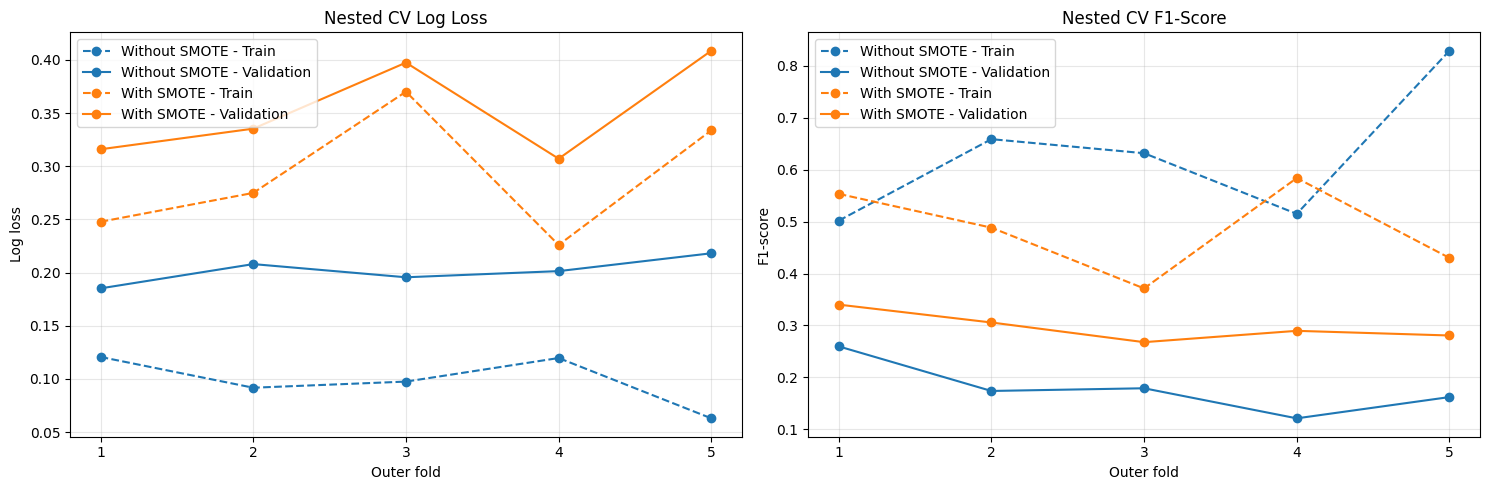

In [64]:
import matplotlib.pyplot as plt

folds = range(1, outer_cv.get_n_splits() + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = {"Without SMOTE": "tab:blue", "With SMOTE": "tab:orange"}

for model_name, scores in cv_comparison.items():
    color = colors[model_name]
    axes[0].plot(
        folds,
        -scores["train_neg_log_loss"],
        marker="o",
        linestyle="--",
        color=color,
        label=f"{model_name} - Train",
    )
    axes[0].plot(
        folds,
        -scores["test_neg_log_loss"],
        marker="o",
        color=color,
        label=f"{model_name} - Validation",
    )
    axes[1].plot(
        folds,
        scores["train_f1"],
        marker="o",
        linestyle="--",
        color=color,
        label=f"{model_name} - Train",
    )
    axes[1].plot(
        folds,
        scores["test_f1"],
        marker="o",
        color=color,
        label=f"{model_name} - Validation",
    )

axes[0].set(title="Nested CV Log Loss", xlabel="Outer fold", ylabel="Log loss")
axes[1].set(title="Nested CV F1-Score", xlabel="Outer fold", ylabel="F1-score")
for axis in axes:
    axis.set_xticks(list(folds))
    axis.legend()
    axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Final Test-Set Evaluation

Evaluate the tuned best estimators on the same untouched test set. Reuse the shared utility for all classification metrics and confusion matrices; the classification reports and metric comparison are presented as DataFrames and plots.

In [65]:
from sklearn.metrics import classification_report

models = {
    "XGBoost - Without SMOTE": best_without_smote,
    "XGBoost - With SMOTE": best_with_smote,
}

evaluation_results = evaluate_classifiers(models, X_test, y_test)
evaluation_results

,XGBoost - Without SMOTE,XGBoost - With SMOTE
Accuracy,0.9354,0.8851
Balanced Accuracy,0.5479,0.7332
Precision,0.5000,0.2946
Sensitivity (Recall),0.1029,0.5588
Specificity,0.9929,0.9076
NPV,0.9413,0.9675
F1-Score,0.1707,0.3858
ROC-AUC,0.8631,0.8389
PR-AUC,0.3839,0.3366
Brier Score,0.0483,0.0918


In [66]:
classification_reports = pd.concat(
    {
        model_name: pd.DataFrame(
            classification_report(
                y_test,
                model.predict(X_test),
                labels=[0, 1],
                target_names=["No Diabetes", "Diabetes"],
                output_dict=True,
                zero_division=0,
            )
        ).T
        for model_name, model in models.items()
    },
    names=["Model", "Class / Metric"],
).round(4)
classification_reports

precision  recall  f1-score    support
Model                   Class / Metric                                        
XGBoost - Without SMOTE No Diabetes        0.9413  0.9929    0.9664   985.0000
                        Diabetes           0.5000  0.1029    0.1707    68.0000
                        accuracy           0.9354  0.9354    0.9354     0.9354
                        macro avg          0.7206  0.5479    0.5686  1053.0000
                        weighted avg       0.9128  0.9354    0.9150  1053.0000
XGBoost - With SMOTE    No Diabetes        0.9675  0.9076    0.9366   985.0000
                        Diabetes           0.2946  0.5588    0.3858    68.0000
                        accuracy           0.8851  0.8851    0.8851     0.8851
                        macro avg          0.6311  0.7332    0.6612  1053.0000
                        weighted avg       0.9241  0.8851    0.9010  1053.0000

In [67]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import ClassifierMixin
from sklearn.metrics import ConfusionMatrixDisplay


def plot_confusion_matrices(
    models: dict[str, ClassifierMixin],
    X_test: pd.DataFrame,
    y_test: pd.Series,
) -> None:
    for name, model in models.items():
        y_pred = model.predict(X_test)

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_pred,
            display_labels=["No Diabetes", "Diabetes"],
            cmap="Blues",
        )

        plt.title(name)
        plt.tight_layout()
        plt.show()

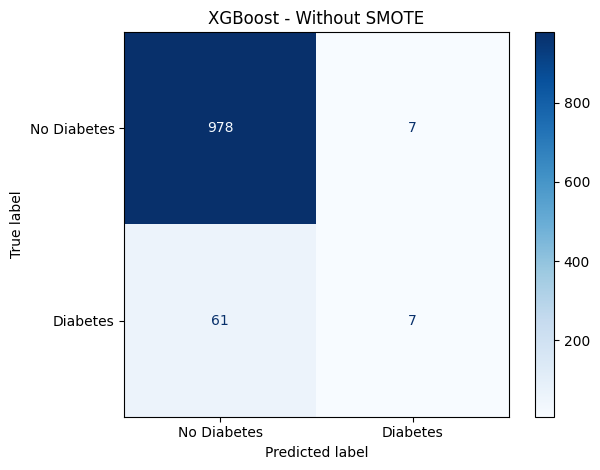

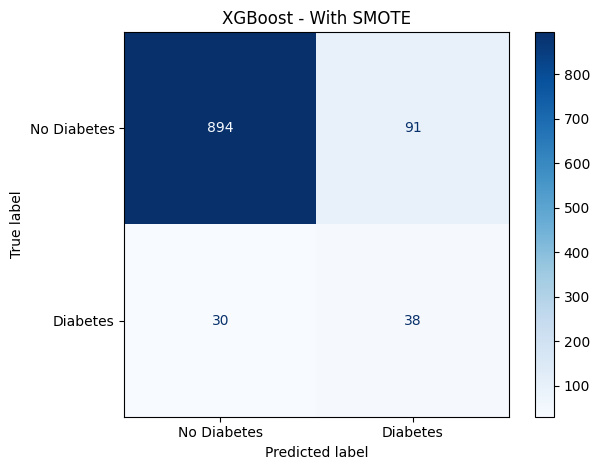

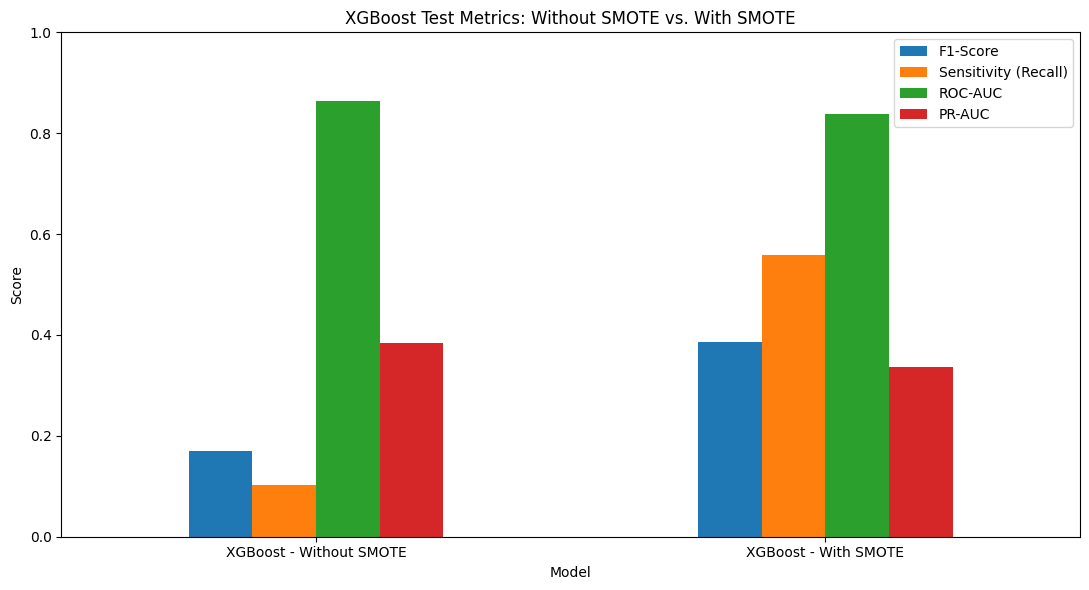

In [68]:
plot_confusion_matrices(models, X_test, y_test)

comparison_metrics = evaluation_results.loc[
    ["F1-Score", "Sensitivity (Recall)", "ROC-AUC", "PR-AUC"]
].T
comparison_metrics.plot(kind="bar", figsize=(11, 6))
plt.title("XGBoost Test Metrics: Without SMOTE vs. With SMOTE")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()